# Knapsack Problem Benchmarking with IBM Torino Backend

This notebook benchmarks variational quantum algorithms on QUBO **Knapsack Problems** using the **IBM Torino** backend architecture.

- **Target Architecture:** IBM Quantum Torino (133-qubit Heron-class processor)
- **Backend Reference:** [`FakeTorino`](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/fake-provider-fake-torino) from `qiskit_ibm_runtime.fake_provider` (with optional switch to live cloud runtime)
- **Algorithms Evaluated:**
  1. `MomentumBuilder` (Adaptive ansatz growth guided by parameter momentum)
  2. `MomentumSA_Phased` (Momentum growth followed by simulated annealing)
  3. `MomentumSA_Merged` (Interleaved momentum ansatz expansion with simulated annealing)
  4. `ADAPT-VQE` (Standard adaptive derivative-assembled pseudo-trotter VQE)

---

## Cell 1 - Imports & Environment Setup

In [1]:
import os
import sys
import time
import heapq
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate workspace and repository directories
cwd = Path.cwd().resolve()
ansatz_pruning_dir = None
for candidate in [cwd, *cwd.parents]:
    if (candidate / "AdaptVQE.py").exists():
        ansatz_pruning_dir = candidate
        break
    if (candidate / "AnsatzPruning" / "AdaptVQE.py").exists():
        ansatz_pruning_dir = candidate / "AnsatzPruning"
        break
if ansatz_pruning_dir is None:
    raise RuntimeError("Could not locate AnsatzPruning directory containing AdaptVQE.py.")
repo_root = ansatz_pruning_dir.parent

# Cache configurations
os.environ.setdefault("MPLCONFIGDIR", str(ansatz_pruning_dir / ".mplconfig"))
os.environ.setdefault("XDG_CACHE_HOME", str(ansatz_pruning_dir / ".cache"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)
Path(os.environ["XDG_CACHE_HOME"]).mkdir(parents=True, exist_ok=True)

# Ensure modules are in path
for p in [repo_root, ansatz_pruning_dir]:
    p_str = str(p)
    if p_str not in sys.path:
        sys.path.insert(0, p_str)

# Qiskit imports
from qiskit import QuantumCircuit
from qiskit.compiler import transpile
from qiskit.circuit import Parameter, ParameterVector
from qiskit.quantum_info import SparsePauliOp, Pauli
from qiskit.primitives import StatevectorEstimator, BackendEstimatorV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator

# IBM Runtime & Fake Provider
from qiskit_ibm_runtime.fake_provider import FakeTorino

# ADAPT-VQE utilities
from AdaptVQE import (
    build_reference_state,
    build_operator_pool,
    run_adapt_vqe,
    extract_result_metrics,
)

print("Libraries loaded successfully.")
print(f"AnsatzPruning directory: {ansatz_pruning_dir}")

Libraries loaded successfully.
AnsatzPruning directory: C:\Users\snappymink\Documents\VQA\AnsatzPruning


## Cell 2 - IBM Torino Backend Configuration

Here we initialize the **Torino** backend. By default, `FakeTorino` provides the exact 133-qubit topology, calibrated T1/T2 times, gate durations, and error rates of `ibm_torino` without needing active cloud credentials.

You can also toggle `USE_REAL_BACKEND = True` to submit directly to IBM Quantum Platform if runtime credentials are saved.

In [2]:
USE_REAL_BACKEND = False  # Set to True if connected to IBM Quantum Runtime

if USE_REAL_BACKEND:
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService()
    backend = service.backend("ibm_torino")
    print(f"Connected to real IBM backend: {backend.name}")
else:
    backend = FakeTorino()
    print(f"Loaded fake backend snapshot: {backend.name}")

print(f"Total Qubits: {backend.num_qubits}")
print(f"Basis Gates: {backend.operation_names}")

# Build an Aer simulator modeled directly from the Torino backend properties
torino_sim = AerSimulator.from_backend(backend)

# Setup preset pass manager for mapping circuits to Torino's heavy-hex coupling map
torino_pm = generate_preset_pass_manager(optimization_level=1, backend=backend)

# Estimator selection:
# - StatevectorEstimator: Fast analytical expectation evaluation
# - BackendEstimatorV2: Shot-based evaluation with backend noise properties
USE_NOISE_SIMULATION = True  # Set True to evaluate energy using noisy Torino AerSimulator

if USE_NOISE_SIMULATION:
    estimator = BackendEstimatorV2(backend=torino_sim)
    print("Estimator: BackendEstimatorV2 (Torino Noise Model)")
else:
    estimator = StatevectorEstimator()
    print("Estimator: StatevectorEstimator (Ideal Analytical Baseline)")

Loaded fake backend snapshot: fake_torino
Total Qubits: 133
Basis Gates: ['switch_case', 'x', 'for_loop', 'cz', 'reset', 'delay', 'measure', 'sx', 'id', 'if_else', 'rz']
Estimator: BackendEstimatorV2 (Torino Noise Model)


In [7]:
print(torino_sim.available_devices())
print(torino_sim.available_methods())
print(torino_sim.configuration())

('CPU',)
('automatic', 'statevector', 'density_matrix', 'stabilizer', 'matrix_product_state', 'extended_stabilizer', 'unitary', 'superop')


## Cell 3 - Benchmark Hyperparameters & Style

In [12]:
TRIALS = 3
COBYLA_MAXITER = 200
BETA1 = 0.9
BETA2 = 0.99
MB_ITERS = 3
SA_RUNS = 100
ADAPT_OPTIMIZER_MAXITER = 200

METHOD_ORDER = ["MomentumBuilder", "MomentumSA_Phased", "MomentumSA_Merged", "ADAPT-VQE"]
METHOD_COLORS = {
    "MomentumBuilder": "#E57373",
    "MomentumSA_Phased": "#9575CD",
    "MomentumSA_Merged": "#FFB74D",
    "ADAPT-VQE": "#4DB6AC",
}

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 10)

## Cell 4 - Knapsack Hamiltonian Definitions (Problems 13–24)

We formulate the 0-1 Knapsack problem into a QUBO Hamiltonian:
$$\mathcal{H} = -\sum_{i=1}^n v_i x_i + P \left(\sum_{i=1}^n w_i x_i - W\right)^2$$
with binary mapping $x_i = \frac{I - Z_i}{2}$.

In [13]:
def buildKnapsackHamiltonian(values, weights, W, P):
    """
    Build QUBO Knapsack Hamiltonian using Pauli operators.
    Encoding: x_i = (1 - Z_i) / 2
    H = -sum_i v_i x_i + P*(sum_i w_i x_i - W)^2
    """
    n = len(values)
    pauli_terms = []

    # VALUE TERM: -sum_i v_i * (1 - Z_i)/2
    for i, v in enumerate(values):
        pauli_terms.append((Pauli("I" * n), -v / 2))
        p = ["I"] * n
        p[n - 1 - i] = "Z"
        pauli_terms.append((Pauli("".join(p)), v / 2))

    # PENALTY: S^2 diagonal terms
    for i in range(n):
        wi = weights[i]
        pauli_terms.append((Pauli("I" * n), P * wi * wi / 2))
        p = ["I"] * n
        p[n - 1 - i] = "Z"
        pauli_terms.append((Pauli("".join(p)), -P * wi * wi / 2))

    # PENALTY: cross terms
    for i in range(n):
        for j in range(i + 1, n):
            wi, wj = weights[i], weights[j]
            pauli_terms.append((Pauli("I" * n), P * wi * wj / 2))
            p = ["I"] * n
            p[n - 1 - i] = "Z"
            pauli_terms.append((Pauli("".join(p)), -P * wi * wj / 2))
            p = ["I"] * n
            p[n - 1 - j] = "Z"
            pauli_terms.append((Pauli("".join(p)), -P * wi * wj / 2))
            p = ["I"] * n
            p[n - 1 - i] = "Z"
            p[n - 1 - j] = "Z"
            pauli_terms.append((Pauli("".join(p)), P * wi * wj / 2))

    # PENALTY: -2 W S
    for i, wi in enumerate(weights):
        pauli_terms.append((Pauli("I" * n), -P * W * wi))
        p = ["I"] * n
        p[n - 1 - i] = "Z"
        pauli_terms.append((Pauli("".join(p)), P * W * wi))

    # PENALTY: + W^2
    pauli_terms.append((Pauli("I" * n), P * W * W))

    paulis, coeffs = zip(*pauli_terms)
    return SparsePauliOp(paulis, coeffs).simplify()


def compute_knapsack_expected(values, weights, W, P):
    """Brute-force exact minimum energy for the knapsack QUBO."""
    best = float("inf")
    n = len(values)
    for mask in range(2**n):
        x = [(mask >> i) & 1 for i in range(n)]
        val = sum(v * xi for v, xi in zip(values, x))
        wt  = sum(w * xi for w, xi in zip(weights, x))
        cost = -val + P * (wt - W) ** 2
        best = min(best, cost)
    return best


_KNAPSACK_P = 0.5  # Soft penalty for rich gradient landscapes

_KNAPSACK_DEFS = {
    #          values (x2 scaled)                weights               W
    13: ([20, 16, 12,  8,  4],          [2, 2, 2, 2, 2],          5),   # 5 qubits
    14: ([40, 10, 10, 10, 10],          [4, 1, 1, 1, 1],          4),   # 5 qubits
    15: ([14, 14, 14, 14, 14, 14],      [1, 2, 1, 2, 1, 2],       6),   # 6 qubits
    16: ([10, 12, 14, 16, 18, 20],      [1, 1, 2, 2, 3, 3],       6),   # 6 qubits
    17: ([20, 18, 16, 14, 12, 10],      [3, 3, 2, 2, 1, 1],       6),   # 6 qubits
    18: ([24, 20, 16, 12,  8,  4,  2],  [3, 3, 2, 2, 1, 1, 1],   7),   # 7 qubits
    19: ([12, 12, 12, 12, 12, 12, 12],  [2, 2, 2, 2, 2, 2, 2],   6),   # 7 qubits
    20: ([16, 14, 12, 10,  8,  6,  4],  [1, 2, 1, 3, 1, 2, 1],   5),   # 7 qubits
    21: ([30, 20, 16, 12,  8,  4],      [4, 3, 2, 2, 1, 1],       5),   # 6 qubits
    22: ([50, 40,  6,  6,  6,  6],      [5, 4, 1, 1, 1, 1],       6),   # 6 qubits
    23: ([26, 16, 10,  6,  4,  2,  2],  [3, 2, 2, 1, 1, 1, 1],   6),   # 7 qubits
    24: ([32, 16,  8,  4,  2,  2,  2],  [4, 3, 2, 1, 1, 1, 1],   7),   # 7 qubits
}


def create_knapsack_hamiltonian(problem_id):
    """Return (H, expected_energy, n_qubits) for knapsack problems 13-24."""
    if problem_id not in _KNAPSACK_DEFS:
        raise ValueError(f"Unknown knapsack problem {problem_id}")
    values, weights, W = _KNAPSACK_DEFS[problem_id]
    H = buildKnapsackHamiltonian(values, weights, W, _KNAPSACK_P)
    expected = compute_knapsack_expected(values, weights, W, _KNAPSACK_P)
    return H, expected, len(values)

print("Knapsack Hamiltonians initialized.")

Knapsack Hamiltonians initialized.


## Cell 5 - Evaluation Utilities & Torino Transpilation

We provide functions for calculating expectation values and parameter-shift gradients, with utilities to measure circuit depth and 2-qubit gate counts compiled directly to Torino's heavy-hex layout.

In [19]:
def scalarize(val):
    """Extract a clean float from primitive output arrays or floats."""
    if isinstance(val, np.ndarray):
        if val.ndim == 0:
            return float(np.real(val.item()))
        return float(np.real(val[-1]))
    if isinstance(val, (list, tuple)):
        return scalarize(np.array(val))
    return float(np.real(val))

pm = generate_preset_pass_manager(backend=estimator.backend, optimization_level=1)

def cost_func(params, circuit, hamiltonian, estimator, pass_manager=None):
    """Evaluate expectation value after transpiling to valid backend basis gates."""
    # Transpile circuit to resolve unhandled instructions like 'rx'
    if pass_manager is not None:
        transpiled_circ = pass_manager.run(circuit)
    else:
        transpiled_circ = pm.run(circuit)
        
    isa_obs = hamiltonian.apply_layout(transpiled_circ.layout)
    pub = (transpiled_circ, isa_obs, params)
    
    evs = estimator.run([pub]).result()[0].data.evs
    return evs
# def cost_func(params, circuit, hamiltonian, estimator, pass_manager=None):
#     """Evaluate expectation value using the configured estimator."""
#     if pass_manager is not None:
#         isa_circ = pass_manager.run(circuit)
#         isa_obs = hamiltonian.apply_layout(isa_circ.layout)
#         pub = (isa_circ, isa_obs, params)
#     else:
#         pub = (circuit, hamiltonian, params)
#     evs = estimator.run([pub]).result()[0].data.evs
#     return evs


def gradi(i, params, circuit, hamiltonian, estimator, pass_manager=None):
    """Parameter-shift rule gradient calculation for parameter index i."""
    delta = np.zeros(len(params))
    delta[i] = math.pi / 2
    costp = cost_func(params + delta, circuit, hamiltonian, estimator, pass_manager)
    costm = cost_func(params - delta, circuit, hamiltonian, estimator, pass_manager)
    grad = (scalarize(costp) - scalarize(costm)) / 2.0
    return grad


def evaluate_energy(circuit, H, params, estimator, pass_manager=None):
    """Evaluate scalar energy for circuit with given parameters."""
    # obs = [*H.paulis, H]
    evs = cost_func(params, circuit, H, estimator, pass_manager)
    return scalarize(evs)


def get_torino_metrics(circuit, pass_manager):
    """Transpile circuit to Torino and extract physical depth and 2-qubit gate count."""
    try:
        isa_circ = pass_manager.run(circuit)
        depth = isa_circ.depth()
        # Count 2-qubit gates (cz/ecr)
        two_q_gates = sum(1 for inst in isa_circ.data if inst.operation.num_qubits == 2)
        return depth, two_q_gates
    except Exception as e:
        return circuit.depth(), 0

## Cell 6 - Momentum Ansatz Builder & Simulated Annealing

In [15]:
def momen_layer(it, n, momentum, radius=1, keep=2):
    lay = QuantumCircuit(n)
    params, inds = [], []
    actual_keep = min(keep, len(momentum))

    for i in range(actual_keep):
        if len(momentum) == 0:
            break
        m_val, ind = heapq.heappop(momentum)
        angle = Parameter(f"it{it}_q{i}")
        params.append(1)
        inds.append(ind)
        lay.rx(angle, ind)
        for r in range(1, radius + 1):
            if ind + r < n:
                lay.cx(ind, ind + r)
            if ind - r >= 0:
                lay.cx(ind, ind - r)
    return lay, params, inds


def MomentumBuilder(params, inds, ansatz, circuit, hamiltonian, estimator, beta1, beta2, iters=2):
    n = circuit.num_qubits
    M = np.zeros(len(params))
    currCirc = QuantumCircuit(n).compose(ansatz)
    #observables = [*hamiltonian.paulis, hamiltonian]
    observables = hamiltonian

    for it in range(iters):
        accumulator = []
        for i in range(len(params)):
            grad_i = abs(gradi(i, params, currCirc, observables, estimator))
            M[i] = beta1 * M[i] + (1 - beta1) * grad_i
            heapq.heappush(accumulator, (-M[i], inds[i]))

        keep = max(2, min(n // 2, len(accumulator)))
        mLayer, nparams, ninds = momen_layer(it, n, accumulator, keep=keep)
        params = params + nparams
        inds = inds + ninds
        M = np.concatenate((M, np.zeros(len(nparams))))
        ansatz = ansatz.compose(mLayer)
        currCirc = circuit.compose(ansatz)

    return circuit.compose(ansatz)


def simulated_annealing(optimization_runs, initial_params, circuit, simulator, observables, estimator):
    def evaluate(p):
        return scalarize(cost_func(p, circuit, observables, estimator))

    current = np.array(initial_params)
    current_E = evaluate(current)
    best, best_E = current.copy(), current_E

    for i in range(optimization_runs):
        T = 2.0 * (0.01 / 2.0) ** (i / optimization_runs)
        proposal = current + np.random.normal(0, 0.3 * T, len(current))
        proposal_E = evaluate(proposal)

        if proposal_E < current_E or np.random.random() < np.exp(-(proposal_E - current_E) / T):
            current, current_E = proposal, proposal_E
            if current_E < best_E:
                best, best_E = current.copy(), current_E
    return best


def momentum_sa_phased(params, inds, ansatz, circuit, H, estimator, beta1, beta2, iters, opt_runs):
    opt_ansatz = MomentumBuilder(params, inds, ansatz, circuit, H, estimator, beta1, beta2, iters)
    init_params = np.random.uniform(-np.pi, np.pi, len(opt_ansatz.parameters))
    # obs = [*H.paulis, H]
    obs = H
    final_params = simulated_annealing(opt_runs, init_params, opt_ansatz, None, obs, estimator)
    return opt_ansatz, final_params, scalarize(cost_func(final_params, opt_ansatz, obs, estimator))


def momentum_sa_merged(params, inds, ansatz, circuit, H, estimator, beta1, beta2, iters, opt_runs):
    n = circuit.num_qubits
    # obs = [*H.paulis, H]
    obs = H
    params = list(np.random.uniform(-np.pi, np.pi, len(params)))
    inds = list(inds)
    M = np.zeros(len(params))
    currCirc = QuantumCircuit(n).compose(ansatz)

    for it in range(iters):
        acc = []
        for i in range(len(params)):
            grad_i = abs(gradi(i, np.array(params), currCirc, obs, estimator))
            M[i] = beta1 * M[i] + (1 - beta1) * grad_i
            heapq.heappush(acc, (-M[i], inds[i]))

        keep = max(2, min(n // 2, len(acc)))
        mLayer, nparams, ninds = momen_layer(it, n, acc, keep=keep)
        params += nparams
        inds += ninds
        M = np.concatenate((M, np.zeros(len(nparams))))
        ansatz = ansatz.compose(mLayer)
        currCirc = circuit.compose(ansatz)
        params = list(simulated_annealing(opt_runs, np.array(params), currCirc, None, obs, estimator))

    circuit = circuit.compose(ansatz)
    return circuit, np.array(params), scalarize(cost_func(np.array(params), circuit, obs, estimator))

## Cell 7 - Algorithm Runners with Torino Compilation Profiling

In [16]:
def create_initial_ansatz(n):
    qc = QuantumCircuit(n)
    theta = ParameterVector("theta", n)
    for i in range(n):
        qc.rx(theta[i], i)
    return qc, list(np.random.uniform(-0.5, 0.5, n)), list(range(n))


def run_momentum_builder_bench(H):
    n = H.num_qubits
    ansatz, params, inds = create_initial_ansatz(n)
    t0 = time.perf_counter()
    opt_circuit = MomentumBuilder(params, inds, ansatz, QuantumCircuit(n), H, estimator, BETA1, BETA2, MB_ITERS)
    final_params = np.ones(len(opt_circuit.parameters))
    energy = evaluate_energy(opt_circuit, H, final_params, estimator)
    elapsed = time.perf_counter() - t0
    depth, cx_count = get_torino_metrics(opt_circuit, torino_pm)
    return energy, elapsed, len(opt_circuit.parameters), depth, cx_count


def run_momentum_sa_phased_bench(H):
    n = H.num_qubits
    ansatz, params, inds = create_initial_ansatz(n)
    t0 = time.perf_counter()
    opt_circ, _, energy = momentum_sa_phased(params, inds, ansatz, QuantumCircuit(n), H, estimator, BETA1, BETA2, MB_ITERS, SA_RUNS)
    elapsed = time.perf_counter() - t0
    depth, cx_count = get_torino_metrics(opt_circ, torino_pm)
    return energy, elapsed, len(opt_circ.parameters), depth, cx_count


def run_momentum_sa_merged_bench(H):
    n = H.num_qubits
    ansatz, params, inds = create_initial_ansatz(n)
    t0 = time.perf_counter()
    opt_circ, _, energy = momentum_sa_merged(params, inds, ansatz, QuantumCircuit(n), H, estimator, BETA1, BETA2, MB_ITERS, SA_RUNS)
    elapsed = time.perf_counter() - t0
    depth, cx_count = get_torino_metrics(opt_circ, torino_pm)
    return energy, elapsed, len(opt_circ.parameters), depth, cx_count


def run_adapt_bench(H):
    t0 = time.perf_counter()
    result = run_adapt_vqe(
        hamiltonian=H,
        initial_state=build_reference_state(H.num_qubits, angle=1.0),
        operator_pool=build_operator_pool(H.num_qubits),
        max_iterations=max(12, H.num_qubits),
        gradient_threshold=1e-6,
        eigenvalue_threshold=1e-8,
        optimizer_maxiter=ADAPT_OPTIMIZER_MAXITER,
    )
    elapsed = time.perf_counter() - t0
    metrics = extract_result_metrics(result)
    energy = float(np.real(metrics["energy"]))
    opt_circuit = metrics.get("optimal_circuit")
    params = metrics.get("num_parameters") or (opt_circuit.num_parameters if opt_circuit else 0)
    if opt_circuit is not None:
        depth, cx_count = get_torino_metrics(opt_circuit, torino_pm)
    else:
        depth, cx_count = 0, 0
    return energy, elapsed, int(params), depth, cx_count, metrics.get("num_iterations")

## Cell 8 - Problem Suite Selection

In [17]:
selected_problems = []

print("Loading Knapsack Problems (13 to 24) for Torino Backend Benchmarking...")
for pid in range(13, 25):
    H, expected, n_qubits = create_knapsack_hamiltonian(pid)
    selected_problems.append((pid, H, expected, n_qubits))
    print(f"  Problem {pid:2d} | Qubits: {n_qubits} | Expected Min Energy: {expected:6.2f} | Pauli Terms: {len(H)}")

print("\nTotal problems ready for benchmarking:", len(selected_problems))

Loading Knapsack Problems (13 to 24) for Torino Backend Benchmarking...
  Problem 13 | Qubits: 5 | Expected Min Energy: -51.50 | Pauli Terms: 16
  Problem 14 | Qubits: 5 | Expected Min Energy: -72.00 | Pauli Terms: 16
  Problem 15 | Qubits: 6 | Expected Min Energy: -79.50 | Pauli Terms: 22
  Problem 16 | Qubits: 6 | Expected Min Energy: -72.00 | Pauli Terms: 22
  Problem 17 | Qubits: 6 | Expected Min Energy: -72.00 | Pauli Terms: 22
  Problem 18 | Qubits: 7 | Expected Min Energy: -72.00 | Pauli Terms: 29
  Problem 19 | Qubits: 7 | Expected Min Energy: -54.00 | Pauli Terms: 29
  Problem 20 | Qubits: 7 | Expected Min Energy: -56.00 | Pauli Terms: 29
  Problem 21 | Qubits: 6 | Expected Min Energy: -61.50 | Pauli Terms: 22
  Problem 22 | Qubits: 6 | Expected Min Energy: -90.00 | Pauli Terms: 22
  Problem 23 | Qubits: 7 | Expected Min Energy: -57.50 | Pauli Terms: 29
  Problem 24 | Qubits: 7 | Expected Min Energy: -55.50 | Pauli Terms: 29

Total problems ready for benchmarking: 12


## Cell 9 - Benchmark Execution Loop

In [20]:
results = []

print("=" * 85)
print(f"STARTING BENCHMARK: {len(selected_problems)} Problems x {TRIALS} Trials on Torino Architecture")
print("=" * 85)

for prob_id, H, expected, n_qubits in selected_problems:
    print(f"\n>>> Problem {prob_id:2d} (Qubits: {n_qubits}, Expected: {expected:.2f})")
    print("-" * 85)

    for trial in range(TRIALS):
        np.random.seed(1000 + prob_id * 10 + trial)
        print(f"  Trial {trial + 1}/{TRIALS}:")

        # 1. MomentumBuilder
        e, t, p, d, cx = run_momentum_builder_bench(H)
        gap = e - expected
        print(f"    MomentumBuilder   : E = {e:7.2f} | Gap = {gap:6.2f} | {t:.1f}s | Torino Depth = {d:3d}")
        results.append((prob_id, trial + 1, "MomentumBuilder", e, t, p, d, cx, expected, np.nan))

        # 2. MomentumSA_Phased
        e, t, p, d, cx = run_momentum_sa_phased_bench(H)
        gap = e - expected
        print(f"    MomentumSA_Phased : E = {e:7.2f} | Gap = {gap:6.2f} | {t:.1f}s | Torino Depth = {d:3d}")
        results.append((prob_id, trial + 1, "MomentumSA_Phased", e, t, p, d, cx, expected, np.nan))

        # 3. MomentumSA_Merged
        e, t, p, d, cx = run_momentum_sa_merged_bench(H)
        gap = e - expected
        print(f"    MomentumSA_Merged : E = {e:7.2f} | Gap = {gap:6.2f} | {t:.1f}s | Torino Depth = {d:3d}")
        results.append((prob_id, trial + 1, "MomentumSA_Merged", e, t, p, d, cx, expected, np.nan))

        # 4. ADAPT-VQE
        e, t, p, d, cx, iters = run_adapt_bench(H)
        gap = e - expected
        print(f"    ADAPT-VQE         : E = {e:7.2f} | Gap = {gap:6.2f} | {t:.1f}s | Torino Depth = {d:3d} (iters={iters})")
        results.append((prob_id, trial + 1, "ADAPT-VQE", e, t, p, d, cx, expected, iters))

df = pd.DataFrame(
    results,
    columns=[
        "problem",
        "trial",
        "algorithm",
        "energy",
        "time",
        "params",
        "torino_depth",
        "torino_2q_gates",
        "expected",
        "adapt_iterations",
    ],
)
df["gap"] = df["energy"] - df["expected"]
df["abs_gap"] = abs(df["gap"])
df["algorithm"] = pd.Categorical(df["algorithm"], categories=METHOD_ORDER, ordered=True)
df = df.sort_values(["problem", "trial", "algorithm"]).reset_index(drop=True)

print("=" * 85)
print("BENCHMARK COMPLETE")
print("=" * 85)

STARTING BENCHMARK: 12 Problems x 3 Trials on Torino Architecture

>>> Problem 13 (Qubits: 5, Expected: -51.50)
-------------------------------------------------------------------------------------
  Trial 1/3:
    MomentumBuilder   : E =  -30.68 | Gap =  20.82 | 88.8s | Torino Depth =  26
    MomentumSA_Phased : E =  -40.01 | Gap =  11.49 | 280.2s | Torino Depth =  34
    MomentumSA_Merged : E =  -39.39 | Gap =  12.11 | 659.3s | Torino Depth =  41
    ADAPT-VQE         : E =  -51.50 | Gap =   0.00 | 0.6s | Torino Depth =   6 (iters=6)
  Trial 2/3:
    MomentumBuilder   : E =  -27.81 | Gap =  23.69 | 81.8s | Torino Depth =  30
    MomentumSA_Phased : E =  -47.07 | Gap =   4.43 | 303.1s | Torino Depth =  28
    MomentumSA_Merged : E =  -40.18 | Gap =  11.32 | 642.7s | Torino Depth =  34
    ADAPT-VQE         : E =  -51.50 | Gap =   0.00 | 0.6s | Torino Depth =   6 (iters=6)
  Trial 3/3:
    MomentumBuilder   : E =  -16.41 | Gap =  35.09 | 80.7s | Torino Depth =  35
    MomentumSA_Phased

## Cell 10 - Results & Statistical Comparison

In [21]:
display(df)

print("\n" + "=" * 85)
print("SUMMARY STATISTICS BY ALGORITHM (TORINO ARCHITECTURE)")
print("=" * 85)
summary = df.groupby("algorithm", observed=False).agg({
    "abs_gap": ["mean", "std", "min", "max"],
    "time": ["mean", "std"],
    "params": ["mean", "std"],
    "torino_depth": ["mean", "std"],
    "torino_2q_gates": ["mean", "std"],
    "adapt_iterations": ["mean"],
}).reindex(METHOD_ORDER)
display(summary)

print("\nBest Algorithm per Problem:")
best_per_prob = df.loc[df.groupby("problem")["energy"].idxmin()][
    ["problem", "algorithm", "energy", "expected", "gap", "torino_depth"]
]
display(best_per_prob.sort_values("problem"))

,problem,trial,algorithm,energy,time,params,torino_depth,torino_2q_gates,expected,adapt_iterations,gap,abs_gap
0,13,1,MomentumBuilder,-30.676758,88.811067,11,26,10,-51.5,NaN,2.082324e+01,2.082324e+01
1,13,1,MomentumSA_Phased,-40.012695,280.157166,11,34,10,-51.5,NaN,1.148730e+01,1.148730e+01
2,13,1,MomentumSA_Merged,-39.386719,659.261782,11,41,9,-51.5,NaN,1.211328e+01,1.211328e+01
3,13,1,ADAPT-VQE,-51.500000,0.592627,5,6,0,-51.5,6.0,2.038806e-08,2.038806e-08
4,13,2,MomentumBuilder,-27.806641,81.766941,11,30,11,-51.5,NaN,2.369336e+01,2.369336e+01
...,...,...,...,...,...,...,...,...,...,...,...,...
139,24,2,ADAPT-VQE,-55.500000,1.323413,9,8,0,-55.5,10.0,5.920621e-08,5.920621e-08
140,24,3,MomentumBuilder,-25.562744,115.459489,16,43,16,-55.5,NaN,2.993726e+01,2.993726e+01
141,24,3,MomentumSA_Phased,-44.195557,309.144793,16,44,17,-55.5,NaN,1.130444e+01,1.130444e+01
142,24,3,MomentumSA_Merged,-35.416504,689.529630,16,41,18,-55.5,NaN,2.008350e+01,2.008350e+01



SUMMARY STATISTICS BY ALGORITHM (TORINO ARCHITECTURE)


abs_gap                                            \
                           mean           std           min           max   
algorithm                                                                   
MomentumBuilder    2.949086e+01  8.693242e+00  1.188867e+01  4.917200e+01   
MomentumSA_Phased  1.382880e+01  5.543477e+00  2.580078e+00  2.604602e+01   
MomentumSA_Merged  1.303318e+01  5.016459e+00  2.952148e+00  2.539185e+01   
ADAPT-VQE          3.737010e-08  4.985957e-08  3.149253e-09  1.878674e-07   

                         time                params           torino_depth  \
                         mean        std       mean       std         mean   
algorithm                                                                    
MomentumBuilder    105.080685  11.842892  14.750000  1.762709    38.222222   
MomentumSA_Phased  296.403266  12.086377  14.750000  1.762709    39.666667   
MomentumSA_Merged  677.750893  17.696708  14.750000  1.762709    38.138889   
ADAPT-VQE            1.076706   0.365463   7.083333  1.130739     7.666667   

                            torino_2q_gates           adapt_iterations  
                        std            mean       std             mean  
algorithm                                                               
MomentumBuilder    7.018796       14.583333  2.697883              NaN  
MomentumSA_Phased  7.506188       14.722222  2.742378              NaN  
MomentumSA_Merged  5.812070       14.277778  2.700382              NaN  
ADAPT-VQE          0.755929        0.000000  0.000000         8.083333


Best Algorithm per Problem:


,problem,algorithm,energy,expected,gap,torino_depth
3,13,ADAPT-VQE,-51.5,-51.5,2.038806e-08,6
15,14,ADAPT-VQE,-72.0,-72.0,1.906601e-08,8
27,15,ADAPT-VQE,-79.5,-79.5,3.149253e-09,6
39,16,ADAPT-VQE,-72.0,-72.0,5.555364e-09,8
51,17,ADAPT-VQE,-72.0,-72.0,1.092477e-08,8
63,18,ADAPT-VQE,-72.0,-72.0,6.352069e-08,8
75,19,ADAPT-VQE,-54.0,-54.0,5.728978e-09,8
87,20,ADAPT-VQE,-56.0,-56.0,1.362307e-08,8
99,21,ADAPT-VQE,-61.5,-61.5,2.822834e-08,8
111,22,ADAPT-VQE,-90.0,-90.0,1.878674e-07,8


## Cell 11 - Graphical Visualizations

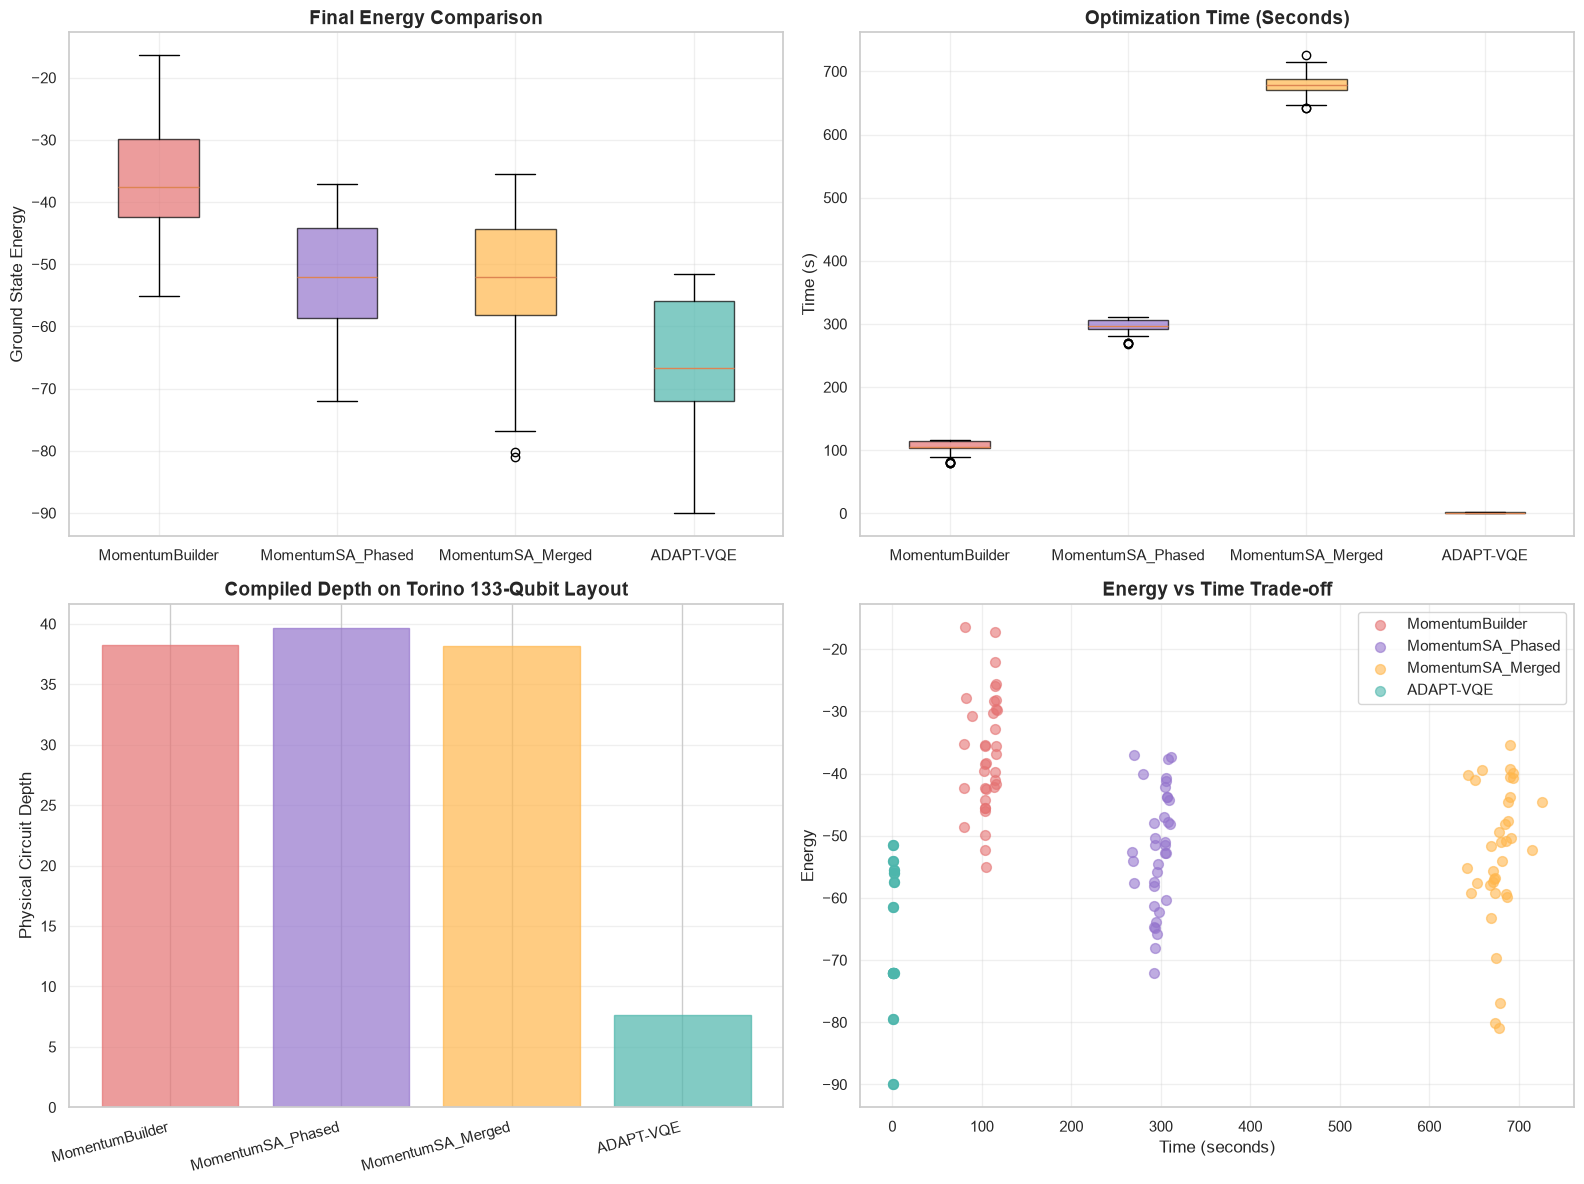

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
available = [alg for alg in METHOD_ORDER if alg in set(df["algorithm"].astype(str))]

# 1. Energy Distribution Boxplot
energy_data = [df[df["algorithm"] == alg]["energy"].dropna().values for alg in available]
bplot1 = axes[0, 0].boxplot(energy_data, tick_labels=available, patch_artist=True)
for patch, alg in zip(bplot1["boxes"], available):
    patch.set_facecolor(METHOD_COLORS.get(alg, "#888888"))
    patch.set_alpha(0.7)
axes[0, 0].set_title("Final Energy Comparison", fontsize=14, fontweight="bold")
axes[0, 0].set_ylabel("Ground State Energy", fontsize=12)
axes[0, 0].grid(True, alpha=0.3)

# 2. Optimization Time Comparison
time_data = [df[df["algorithm"] == alg]["time"].dropna().values for alg in available]
bplot2 = axes[0, 1].boxplot(time_data, tick_labels=available, patch_artist=True)
for patch, alg in zip(bplot2["boxes"], available):
    patch.set_facecolor(METHOD_COLORS.get(alg, "#888888"))
    patch.set_alpha(0.7)
axes[0, 1].set_title("Optimization Time (Seconds)", fontsize=14, fontweight="bold")
axes[0, 1].set_ylabel("Time (s)", fontsize=12)
axes[0, 1].grid(True, alpha=0.3)

# 3. Compiled Torino Circuit Depth
depth_means = df.groupby("algorithm", observed=False)["torino_depth"].mean().reindex(available).dropna()
bars = axes[1, 0].bar(range(len(depth_means)), depth_means.values)
for bar, alg in zip(bars, depth_means.index):
    bar.set_color(METHOD_COLORS.get(alg, "#888888"))
    bar.set_alpha(0.7)
axes[1, 0].set_title("Compiled Depth on Torino 133-Qubit Layout", fontsize=14, fontweight="bold")
axes[1, 0].set_ylabel("Physical Circuit Depth", fontsize=12)
axes[1, 0].set_xticks(range(len(depth_means)))
axes[1, 0].set_xticklabels(depth_means.index, rotation=15, ha="right")
axes[1, 0].grid(True, alpha=0.3, axis="y")

# 4. Energy vs Time Trade-off
for alg in available:
    subset = df[df["algorithm"] == alg]
    axes[1, 1].scatter(
        subset["time"],
        subset["energy"],
        label=alg,
        alpha=0.6,
        s=50,
        color=METHOD_COLORS.get(alg, "#888888"),
    )
axes[1, 1].set_title("Energy vs Time Trade-off", fontsize=14, fontweight="bold")
axes[1, 1].set_xlabel("Time (seconds)", fontsize=12)
axes[1, 1].set_ylabel("Energy", fontsize=12)
axes[1, 1].legend(loc="upper right")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Cell 12 - Performance Summary & Win Counts

In [12]:
means = df.groupby("algorithm", observed=False).mean(numeric_only=True).reindex(METHOD_ORDER).dropna(how="all")

print("=" * 85)
print("PERFORMANCE SUMMARY ON IBM TORINO")
print("=" * 85)

if len(means) > 0:
    display(means[["energy", "abs_gap", "time", "params", "torino_depth", "torino_2q_gates"]])

    if "ADAPT-VQE" in means.index:
        for baseline in ["MomentumBuilder", "MomentumSA_Phased", "MomentumSA_Merged"]:
            if baseline not in means.index:
                continue

            baseline_gap = means.loc[baseline, "abs_gap"]
            adapt_gap = means.loc["ADAPT-VQE", "abs_gap"]
            gap_reduction = np.nan
            if baseline_gap != 0:
                gap_reduction = ((baseline_gap - adapt_gap) / baseline_gap) * 100

            energy_diff = (
                (means.loc[baseline, "energy"] - means.loc["ADAPT-VQE", "energy"])
                / abs(means.loc[baseline, "energy"])
            ) * 100
            speedup = means.loc[baseline, "time"] / means.loc["ADAPT-VQE", "time"]

            print("\n" + "-" * 50)
            print(f"ADAPT-VQE vs {baseline}")
            print("-" * 50)
            print(f"Energy Improvement:  {energy_diff:+7.2f}%")
            print(f"Gap Reduction:       {gap_reduction:+7.2f}%")
            print(f"Speed Ratio:         {speedup:7.2f}x")

    print("\n" + "=" * 85)
    print("WIN COUNT (Best Energy Per Problem)")
    print("=" * 85)
    best = df.loc[df.groupby("problem")["energy"].idxmin()]
    wins = best["algorithm"].value_counts().reindex(METHOD_ORDER).fillna(0).astype(int)
    for alg, count in wins.items():
        print(f"{alg:20s}: {count:2d} / {len(selected_problems)} problems")
else:
    print("No results recorded.")

PERFORMANCE SUMMARY ON IBM TORINO


,energy,abs_gap,time,params,torino_depth,torino_2q_gates
algorithm,,,,,,
MomentumBuilder,-38.017209,2.810779e+01,1.604700,14.750000,37.222222,14.305556
MomentumSA_Phased,-57.563703,8.561297e+00,5.860774,14.750000,39.722222,14.444444
MomentumSA_Merged,-58.034110,8.090890e+00,11.712623,14.750000,37.972222,14.583333
ADAPT-VQE,-66.125000,3.737010e-08,1.131752,7.083333,7.666667,0.000000



--------------------------------------------------
ADAPT-VQE vs MomentumBuilder
--------------------------------------------------
Energy Improvement:   +73.93%
Gap Reduction:       +100.00%
Speed Ratio:            1.42x

--------------------------------------------------
ADAPT-VQE vs MomentumSA_Phased
--------------------------------------------------
Energy Improvement:   +14.87%
Gap Reduction:       +100.00%
Speed Ratio:            5.18x

--------------------------------------------------
ADAPT-VQE vs MomentumSA_Merged
--------------------------------------------------
Energy Improvement:   +13.94%
Gap Reduction:       +100.00%
Speed Ratio:           10.35x

WIN COUNT (Best Energy Per Problem)
MomentumBuilder     :  0 / 12 problems
MomentumSA_Phased   :  0 / 12 problems
MomentumSA_Merged   :  0 / 12 problems
ADAPT-VQE           : 12 / 12 problems
